# Following both Bratu temperature branches

This executable experiment uses the OneSimulation dense linear solver. Change the parameters passed to `experiment` in the final cell. The plotted height is a scalar field; it is not a third spatial coordinate. Outputs below were generated by running this code.

In [1]:
"""Follow both Bratu branches using OneSimulation augmented Newton solves."""
import argparse
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense


def branch(parameter=2.4, intervals=16):
    if parameter <= 0 or intervals < 4 or intervals % 2:
        raise ValueError("Use a positive branch parameter and an even interval count >= 4")
    x = np.linspace(0, 1, intervals+1)
    exact = 2*np.log(np.cosh(parameter/2)/np.cosh(parameter*(x-.5)))
    reference = 2*parameter**2/np.cosh(parameter/2)**2
    state, load = exact[1:-1].copy(), reference
    h = 1/intervals
    for iteration in range(15):
        full = np.r_[0., state, 0.]
        residual = np.r_[(full[:-2]-2*state+full[2:])/h**2 + load*np.exp(state),
                         state[intervals//2-1]-exact[intervals//2]]
        if np.linalg.norm(residual) < 1e-10:
            break
        jacobian = np.zeros((intervals, intervals))
        jacobian[:-1, :-1] = (np.diag(-2/h**2 + load*np.exp(state))
                                  + np.diag(np.ones(intervals-2)/h**2, 1)
                                  + np.diag(np.ones(intervals-2)/h**2, -1))
        jacobian[:-1, -1] = np.exp(state)
        jacobian[-1, intervals//2-1] = 1
        correction = solve_dense(jacobian, -residual)
        state += correction[:-1]
        load += correction[-1]
    assert np.linalg.norm(residual) < 1e-8
    return x, np.r_[0., state, 0.], load, reference, np.linalg.norm(residual)


def experiment(parameter=2.4, intervals=16):
    x, state, load, reference, residual = branch(parameter, intervals)
    print(f"Analytical load: {reference:.9f}; discrete load: {load:.9f}")
    print(f"Augmented Newton residual: {residual:.3e}")
    refined = branch(parameter, 2*intervals)
    assert abs(refined[2]-reference) < abs(load-reference)
    print(f"Load error after doubling the mesh: {abs(refined[2]-reference):.3e}")
    fig = plt.figure(figsize=(10, 4.6), layout="constrained")
    view = fig.add_subplot(121, projection="3d")
    xx, aa = np.meshgrid(np.linspace(0, 1, 45), np.linspace(.3, 5, 45))
    lam = 2*aa**2/np.cosh(aa/2)**2
    field = 2*np.log(np.cosh(aa/2)/np.cosh(aa*(xx-.5)))
    view.plot_surface(xx, lam, field, color="#9dc6b9", alpha=.7, linewidth=0)
    view.plot(x, np.full_like(x, load), state, color="#ad491d", lw=2.5)
    view.set(xlabel="x", ylabel="Load lambda", zlabel="Temperature u", title="Folded family of 1D solutions")
    ax = fig.add_subplot(122)
    ax.plot(x, 2*np.log(np.cosh(parameter/2)/np.cosh(parameter*(x-.5))), label="Analytical same-midpoint profile")
    ax.plot(x, state, "o--", ms=3, label="Augmented OneSimulation solve")
    ax.set(xlabel="x", ylabel="Temperature u")
    ax.legend(fontsize=8)
    fig.savefig("complete-numerics-bratu.png", dpi=170)
    return load, residual




Analytical load: 3.513830356; discrete load: 3.506676842
Augmented Newton residual: 5.459e-13
Load error after doubling the mesh: 1.786e-03


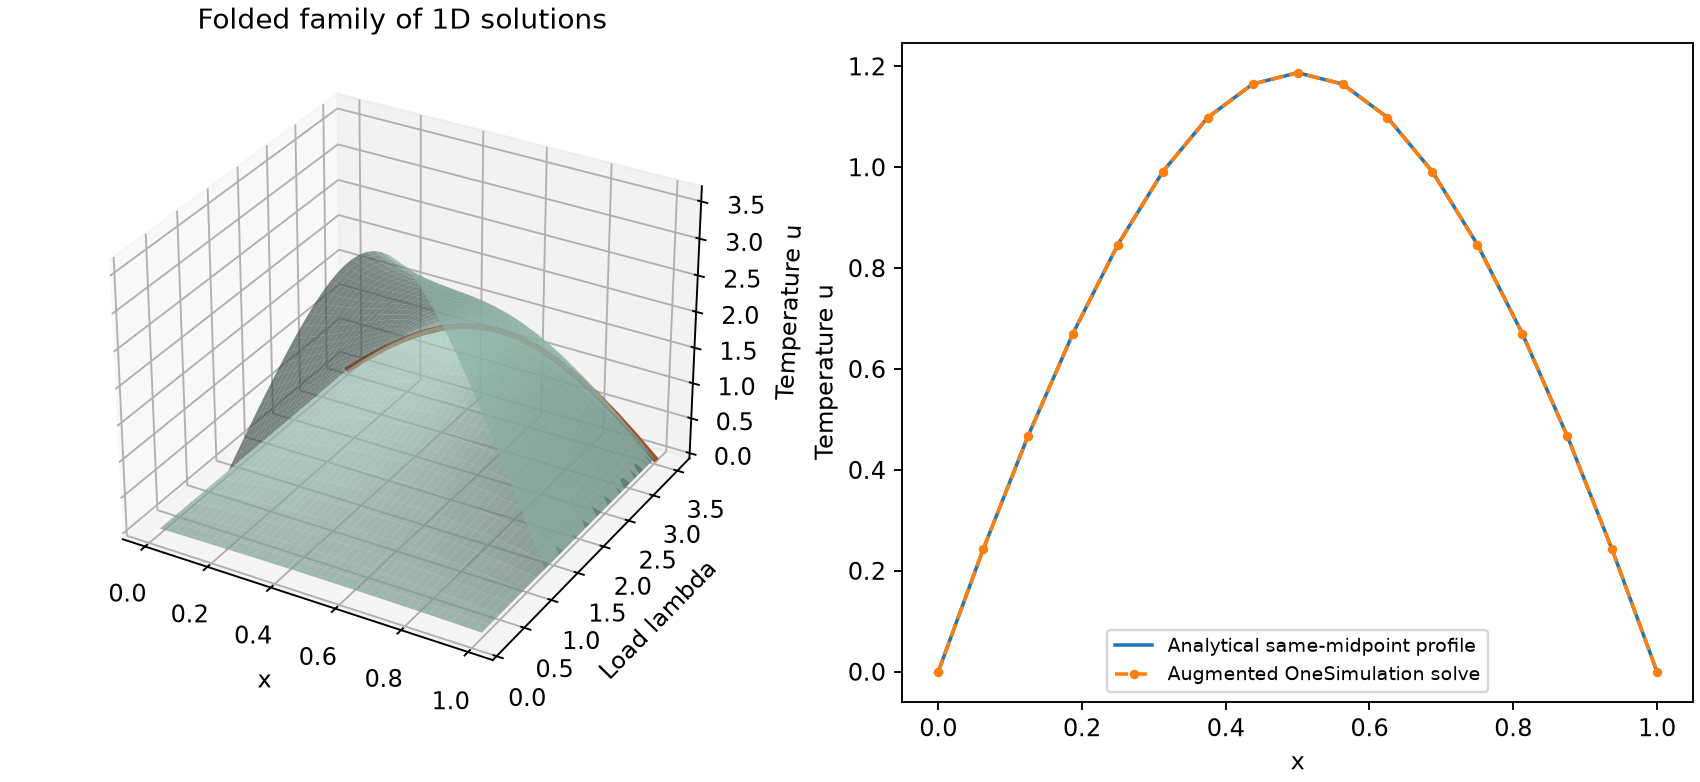

In [2]:
experiment(parameter=2.4, intervals=16)
plt.show()